# Generative-model metrics · 


**Google Colab:** open https://colab.research.google.com/ and upload this `.ipynb` using
**File → Upload notebook**. Use a Python CPU runtime, then **Runtime → Run all**.
Save your own copy so you keep your answers and outputs.

**Local Jupyter / VS Code:** open this file, select a Python **3.10 or newer** kernel,
and run the cells from top to bottom. The first code cell installs any missing core packages
in that kernel's environment. Internet is required to download the reference image, install missing packages, and
optionally download pretrained LPIPS weights. If your environment disallows installation,
use Colab or a virtual environment. After an installation asks for a restart, restart the kernel
and run all again.

**Optional LPIPS:** the default is `RUN_LPIPS = False` to keep the core small. To include it,
change this to `True` in the setup cell. That permits installation of its extra packages and,
on first use, download of the pretrained AlexNet checkpoint (about 233 MB). Keep CPU selected.
The notebook reports a clear skip if optional LPIPS cannot run; it never substitutes random weights.

All plots are displayed and kept in memory. Save this notebook to preserve your outputs. No export step is required. No folder names or absolute paths need editing.

Research content checked **17 September 2026**. Local execution is tested; Colab instructions
follow its official notebook interface. A live hosted Colab session was not used for validation.
[Colab documentation](https://research.google.com/colaboratory/faq.html)

In [20]:
# Run this before the scientific imports. Install only missing packages in THIS kernel.
RUN_LPIPS = True  # True enables optional packages and pretrained-weight download.

import sys
import subprocess
import importlib.util

if sys.version_info < (3, 10):
    raise RuntimeError('Use Python 3.10+ or a current Colab Python runtime.')

requirements = {
    'numpy': 'numpy>=1.23', 'scipy': 'scipy>=1.9',
    'matplotlib': 'matplotlib>=3.6', 'pandas': 'pandas>=1.5',
    'PIL': 'Pillow>=9.1', 'skimage': 'scikit-image>=0.19',
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print('Installing missing core packages:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('Core packages are available; nothing to install.')

LPIPS_SETUP_ERROR = None
if RUN_LPIPS:
    optional = {'torch': 'torch', 'torchvision': 'torchvision', 'lpips': 'lpips==0.1.4'}
    optional_missing = [package for module, package in optional.items()
                        if importlib.util.find_spec(module) is None]
    if optional_missing:
        try:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', *optional_missing])
        except subprocess.CalledProcessError as exc:
            LPIPS_SETUP_ERROR = str(exc)
            print('Optional LPIPS installation failed. The core experiments can still run.')
print('Python:', sys.version.split()[0], '| optional LPIPS enabled:', RUN_LPIPS)

Core packages are available; nothing to install.
Python: 3.11.7 | optional LPIPS enabled: True


## Three questions for today

1. Did we reconstruct one image well?
2. Do two collections have similar statistics?
3. Are generated examples plausible and varied?



### Opening: ask the right question · 

**Goal:** choose between an image-pair test and a collection-level test.

**Key idea:** “If we restore a damaged photograph, there is a particular correct image to compare
against. If we generate new cats, there is no correct cat photo for each output. We compare
whole collections instead.”

**Ask:** “Would comparing a newly generated cat to one arbitrary real cat be fair?”
**Expected answer:** no; a valid new cat can differ from that particular reference.

**Vocabulary:** a feature vector is a list of numbers produced by a chosen representation.
One image becomes one point; many images become a cloud. Its length is not the image width.

Run the setup below. It imports libraries and checks versions; it is not a learning objective.

In [21]:
import sys, time, json, importlib.metadata
import io, base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, shift
from scipy.spatial.distance import cdist
from scipy.stats import wasserstein_distance
from skimage.metrics import structural_similarity
from PIL import Image
from IPython.display import display

START = time.perf_counter()
SEED = 20260917
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

# Store PNGs in memory: no assumptions about a working directory or writable project folder.
figure_files = {}
def finish_figure(name):
    plt.tight_layout()
    buffer = io.BytesIO()
    plt.savefig(buffer, format='png', dpi=160, bbox_inches='tight')
    figure_files[f'{name}.png'] = buffer.getvalue()
    plt.show()
    plt.close()

versions = {'python': sys.version.split()[0]}
for package in ['numpy', 'scipy', 'matplotlib', 'pandas', 'Pillow', 'scikit-image',
                'torch', 'torchvision', 'lpips']:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = 'not installed (optional for last three)'
display(pd.Series(versions, name='version').to_frame())

,version
python,3.11.7
numpy,1.26.4
scipy,1.16.3
matplotlib,3.8.0
pandas,2.1.4
Pillow,10.2.0
scikit-image,0.22.0
torch,2.3.0
torchvision,0.18.0
lpips,0.1.4


Reference image ready: (128, 128, 3)


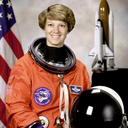

In [22]:
# Download the public-domain NASA astronaut photograph from scikit-image.
from urllib.request import urlopen
from io import BytesIO

IMAGE_URL = "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.22.0/skimage/data/astronaut.png"
with urlopen(IMAGE_URL, timeout=30) as response:
    image = Image.open(BytesIO(response.read())).convert("RGB")

# Keep the experiment small and normalize pixel values to [0, 1].
image = image.resize((128, 128), Image.Resampling.LANCZOS)
ref = np.asarray(image, dtype=np.float32) / 255.0
print("Reference image ready:", ref.shape)
display(image)

### 1. Did we reconstruct the reference image well? · 

**Task:** evaluating reconstruction/restoration, such as denoising an image or reconstructing
it with an autoencoder. The clean astronaut image is our known target.

**Experiment idea:** noise, blur, displacement, and brightness imitate different errors an
output could contain. We make these changes ourselves to isolate their effects. **We are
not running a restoration model, and the corrupted images are not trained-generator outputs.**

**Goal:** understand why “correct pixels” and “looks similar” are different criteria.

**Key idea:** “Suppose these were competing reconstructions of the same photograph. Which would
you prefer? Now let's see whether the scores agree with us.”

| Score | Simple meaning | Better direction | Uses a pretrained network? |
|---|---|---|---|
| MSE | Average squared error at matching pixels | Lower; identical = 0 | No |
| PSNR | The same pixel error on a logarithmic scale | Higher; identical = infinity | No |
| SSIM | Compare local brightness, contrast, and patterns | Higher; identical = 1 | No |
| LPIPS | Compare learned visual features | Lower; identical = 0 | Yes: AlexNet here, plus learned LPIPS calibration |

**Predict before the table:** which alteration looks worst? Does shifting the image destroy
its content, or mainly its pixel alignment?

Optional formula reference (not a derivation exercise), for normalized pixel values:

$$\mathrm{MSE}=\frac{1}{N}\sum_i(x_i-y_i)^2,\qquad
\mathrm{PSNR}=-10\log_{10}(\mathrm{MSE}).$$

Here N counts all pixel-channel values. For fixed pixel range, MSE and PSNR give the same
ranking in opposite directions. SSIM can be negative; LPIPS is not a probability.

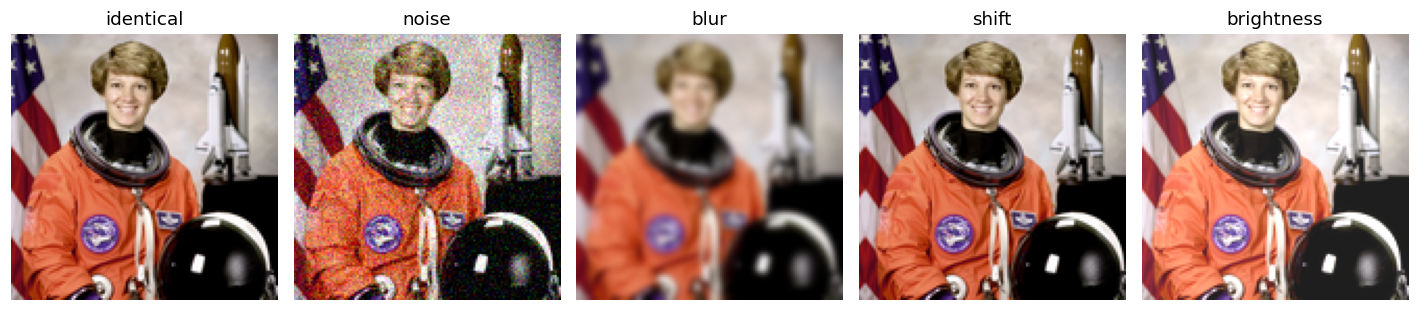

In [23]:
noise_rng = np.random.default_rng(SEED + 1)
NOISE_STD = 0.09 # 1
BLUR_SIGMA=  1.5  # 1.5
SHIFT_PIXELS = 3  #1
images = {
    'identical': ref.copy(),
    'noise': np.clip(ref + noise_rng.normal(0, NOISE_STD, ref.shape), 0, 1),
    'blur': gaussian_filter(ref, sigma=(BLUR_SIGMA, BLUR_SIGMA, 0)),
    'shift': shift(ref, (0, SHIFT_PIXELS, 0), order=1, mode='reflect'),
    'brightness': np.clip(ref + 0.12, 0, 1),
}
fig, axes = plt.subplots(1, len(images), figsize=(13, 3))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img); ax.set_title(name); ax.axis('off')
finish_figure('01_image_corruptions')

In [24]:
rows = []
for name, img in images.items():
    mse = float(np.mean((ref.astype(np.float64) - img)**2))
    rows.append({'image': name, 'MSE ↓': mse,
                 'PSNR dB ↑': np.inf if mse == 0 else -10*np.log10(mse),
                 'SSIM ↑': structural_similarity(ref, img, channel_axis=-1, data_range=1.0)})
paired_scores = pd.DataFrame(rows).set_index('image')
display(paired_scores.round(5))

,MSE ↓,PSNR dB ↑,SSIM ↑
image,,,
identical,0.00000,inf,1.00000
noise,0.00704,21.52419,0.64656
blur,0.00843,20.74314,0.73565
shift,0.05181,12.85615,0.27949
brightness,0.01399,18.54060,0.86824


#### Before LPIPS: which model is doing what?

**Key idea:** “We borrow a pretrained recognition network as a measuring instrument. It is not
the generator we are evaluating.”

AlexNet produces visual features at five selected layers. LPIPS compares corresponding
features, applies learned calibration weights, averages over locations, and sums the layers.
AlexNet weights learned image recognition; the additional calibration weights learned from
human similarity judgments. Both stay fixed here.

The library also supports VGG and SqueezeNet backbones, but keep **AlexNet fixed** for this
comparison: changing the measuring network changes the metric. LPIPS needs RGB tensors
in the expected layout/range; our helper converts them to `(1, 3, H, W)` and `[-1,1]`.

`RUN_LPIPS = False` in the first setup cell skips this optional experiment. Set it to
True and rerun from the top to permit installation and pretrained-weight download. If it
cannot run, read the explanation and continue with the core experiments. No random weights
are substituted, and no LPIPS score is claimed when it is skipped.

Source: [official LPIPS implementation](https://github.com/richzhang/PerceptualSimilarity).

In [25]:
# Optional real pretrained LPIPS. RUN_LPIPS is selected in the first setup cell.
lpips_status = 'skipped by choice; set RUN_LPIPS=True in setup and rerun to enable'
if RUN_LPIPS and LPIPS_SETUP_ERROR is not None:
    lpips_status = 'skipped: optional package installation failed'
elif RUN_LPIPS:
    try:
        import torch, lpips
        torch.set_num_threads(2)
        # Downloads pretrained AlexNet automatically on first use if not already cached.
        metric = lpips.LPIPS(net='alex', version='0.1', verbose=False).cpu().eval()
        def lpips_tensor(img):
            tensor = torch.from_numpy(np.ascontiguousarray(img)).float()
            return tensor.permute(2, 0, 1)[None]*2-1
        with torch.inference_mode():
            reference_batch = lpips_tensor(ref)
            scores = [float(metric(reference_batch, lpips_tensor(img)).item())
                      for img in images.values()]
        assert abs(scores[0]) < 1e-6, 'Identical images should have near-zero LPIPS.'
        paired_scores['LPIPS ↓'] = scores
        lpips_status = 'executed: pretrained AlexNet + LPIPS v0.1, CPU, RGB [-1,1]'
    except Exception as exc:
        # Keep the rest of the lesson usable, but expose the actual optional failure.
        lpips_status = f'LPIPS unavailable: {type(exc).__name__}: {exc}'
        print('No LPIPS result was computed. Check internet/package compatibility to retry.')
print(lpips_status)
display(paired_scores.round(5))

/opt/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


executed: pretrained AlexNet + LPIPS v0.1, CPU, RGB [-1,1]


,MSE ↓,PSNR dB ↑,SSIM ↑,LPIPS ↓
image,,,,
identical,0.00000,inf,1.00000,0.00000
noise,0.00704,21.52419,0.64656,0.10153
blur,0.00843,20.74314,0.73565,0.36563
shift,0.05181,12.85615,0.27949,0.09302
brightness,0.01399,18.54060,0.86824,0.01485


**What to notice:** “A small shift changes many matching pixels without changing who
is in the picture. Metrics disagree because they measure different properties.” SSIM and
LPIPS are not fully shift-invariant either. A low LPIPS value is not proof of correctness.

**Student activity:** change ONE corruption strength, predict its effect, then rerun the
image and score cells. Restore the setting before comparing with earlier results.


### 2. Do two image collections have similar statistics? ·

**Task:** evaluate a generator that produces new examples, without matching reference images.

**Experiment idea:** treat 2D points as image features so we can SEE what the score misses.
No image feature extractor runs in this section. These are **toy feature distances**, not
benchmark FID, KID, or CMMD values.

**Goal:** understand that matching summary statistics does not mean matching distributions.

**Key idea:** “Real images form one feature cloud and generated images form another. Fréchet
distance compares their centers and covariance summaries—not image 1 against image 1.”

Mean = center. Covariance = spread and directions. A Gaussian summary is an approximation
using these quantities, not a claim that the original cloud is bell-shaped.

**Model connection:** standard FID uses a fixed pretrained **Inception-v3** feature extractor.
KID also uses Inception features, with a different statistical comparison. Replacing the
extractor changes what is measured and the numeric scale; it is not the same standard FID.


In [16]:
def feature_arrays(x, y):# check that all inputs makes sense
    x, y = np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64) #convert to numpy
    if x.ndim != 2 or y.ndim != 2 or x.shape[1] != y.shape[1] or min(len(x), len(y)) < 2: #
        raise ValueError('Need finite (N,d) and (M,d) arrays with N,M >= 2 and the same d.')
    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError('Features must be finite.')
    return x, y

def psd_sqrt(matrix): # claculate a matrix square root safely
    matrix = (matrix + matrix.T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    tolerance = 1e-9 * max(1.0, np.linalg.norm(matrix, 2))
    if eigenvalues.min() < -tolerance:
        raise ValueError('Matrix is not positive semidefinite.')
    return (eigenvectors * np.sqrt(np.maximum(eigenvalues, 0))) @ eigenvectors.T

def frechet_features(x, y): #compare centers and covairances
    x, y = feature_arrays(x, y)
    cx, cy = np.atleast_2d(np.cov(x, rowvar=False)), np.atleast_2d(np.cov(y, rowvar=False)) #calculate covariance matrices
    sx = psd_sqrt(cx)
    value = np.sum((x.mean(0)-y.mean(0))**2) + np.trace(cx + cy - 2*psd_sqrt(sx @ cy @ sx)) #apply the Fréchet formula
    if value < -1e-7 * max(1, np.trace(cx)+np.trace(cy)):
        raise ArithmeticError('Unexpected negative Fréchet value.')
    return float(max(value, 0))  # only tiny floating-point negatives are clipped

#A kernel is a rule for comparing two feature vectors. For this lesson, think of it as a similarity function.

def polynomial_kernel(x, y):
    return (x @ y.T / x.shape[1] + 1)**3

def rbf_kernel(x, y, sigma=1.0):
    if sigma <= 0:
        raise ValueError('sigma must be positive')
    return np.exp(-cdist(x, y, 'sqeuclidean')/(2*sigma**2))

def mmd2(x, y, kernel=rbf_kernel, unbiased=True):
    x, y = feature_arrays(x, y)
    xx, yy, xy = kernel(x, x), kernel(y, y), kernel(x, y)


    '''
    MMD² =
    average real–real similarity + average generated–generated similarity− 2 × average real–generated similarity

    real -real table
              x₁          x₂          x₃
    x₁     self        compare     compare
    x₂     compare     self        compare
    x₃     compare     compare     self
    '''

    if unbiased:
        # U-statistic: exclude self-pairs. May be negative; do not clip.
        a = (xx.sum()-np.trace(xx))/(len(x)*(len(x)-1))
        b = (yy.sum()-np.trace(yy))/(len(y)*(len(y)-1))
    else:
        # V-statistic: includes self-pairs; biased for independent finite samples.
        a, b = xx.mean(), yy.mean()
    return float(a + b - 2*xy.mean())

#### Experiment: same summaries, different locations

**Key idea:** “The reference points sit on the axes; the generated points sit at the corners.
They occupy different locations, but we deliberately made their means and covariances match.”

**Predict:** will Fréchet distance notice the difference?

The code also reports MMD: a comparison built from pairwise similarities. **RBF** gives
nearby points high similarity and distant points low similarity. Its sigma sets the distance
scale. The polynomial row is an optional comparison already in the code below; no extra
derivation is required. We use exact empirical V-statistics for these constructed sets.

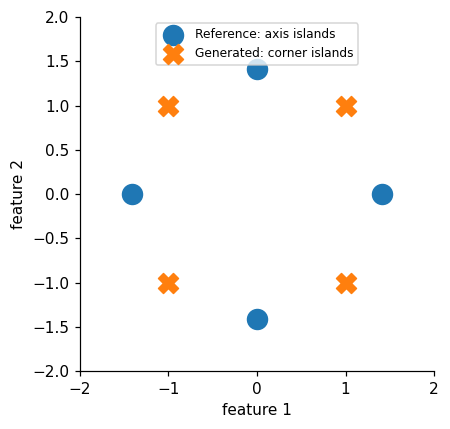

,constructed-set discrepancy
Fréchet feature distance,0.000000
Polynomial MMD² V (same kernel family as KID),0.000000
RBF MMD² V (sigma=1),0.054923


Mean difference: [0. 0.]
Covariance difference:
 [[0. 0.]
 [0. 0.]]


In [17]:
# Constructed finite sets, NOT independent draws: compare exact empirical V-statistics here.
axes_points = np.array([[np.sqrt(2),0],[-np.sqrt(2),0],[0,np.sqrt(2)],[0,-np.sqrt(2)]])
corner_points = np.array([[1,1],[-1,1],[-1,-1],[1,-1]])
moment_p = np.repeat(axes_points, 20, axis=0)
moment_q = np.repeat(corner_points, 20, axis=0)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(*axes_points.T, s=170, label='Reference: axis islands', marker='o')
ax.scatter(*corner_points.T, s=170, label='Generated: corner islands', marker='X')
ax.set(xlim=(-2,2), ylim=(-2,2), xlabel='feature 1', ylabel='feature 2')
ax.set_aspect('equal'); ax.legend(fontsize=8, loc='upper center')
finish_figure('02_moment_blind_spot')
blind_spot = pd.Series({
    'Fréchet feature distance': frechet_features(moment_p, moment_q),
    'Polynomial MMD² V (same kernel family as KID)': mmd2(moment_p, moment_q, polynomial_kernel, False),
    'RBF MMD² V (sigma=1)': mmd2(moment_p, moment_q, rbf_kernel, False),
}, name='constructed-set discrepancy')
display(blind_spot.to_frame().round(6))
print('Mean difference:', moment_p.mean(0)-moment_q.mean(0))
print('Covariance difference:\n', np.cov(moment_p.T)-np.cov(moment_q.T))

**Answer:** Fréchet is essentially zero despite different point locations. The degree-three
polynomial comparison also misses this constructed example because the relevant moments
through degree three match. RBF MMD detects the difference here.

**Key idea:** “A score can only see the information its representation and comparison retain.”

**By the end:** students can explain one blind spot of a collection score. They do not need
to implement MMD, choose a production kernel, or derive matrix square roots.

Sources: [FID](https://arxiv.org/abs/1706.08500), [KID](https://arxiv.org/abs/1801.01401).

### 3. Are outputs plausible AND varied? · 

**Task:** diagnose a generator that looks good but misses part of the real data (mode collapse).
**Experiment idea:** compare balanced samples, samples from only one island, and overly
scattered samples against four real islands. These points are simulated, not image outputs.
**Goal:** separate plausible outputs from coverage of real variety.

**Key idea:** “Beautiful cats every time is not enough if the data also contains dogs and birds.
But generating random nonsense is not useful variety either.” Islands need not represent
literal classes; they stand for different regions of the feature distribution.

Draw circles around points, reaching their k-th nearest OTHER neighbor in the SAME collection.

| Metric | Simple counting rule | Interpretation |
|---|---|---|
| Precision | Generated points inside any real circle / generated count | 0–1; higher suggests plausibility |
| Recall | Real points inside any generated circle / real count | 0–1; higher suggests variety reached |
| Coverage | Real circles containing a generated point / real count | 0–1; higher means more real neighborhoods visited |
| Density | Average real-circle count per generated point, divided by k | Can exceed 1; around 1 is a matched-distribution reference, not a quality percentage |

**What is good?** There is no universal cutoff. Read the metrics together under fixed settings;
even independent samples from the same distribution need not have precision/recall near 1.
Density is not a quantity to maximize blindly.

**Model connection:** these formulas do not specify one mandatory neural network. For images,
choose and report a fixed feature extractor and preprocessing for BOTH collections. In our
2D experiment there is no neural feature extractor at all.

**Predict:** which generator has high precision but misses islands? Which could obtain high
recall by spreading out? Focus on the plots and table, not the helper implementation.

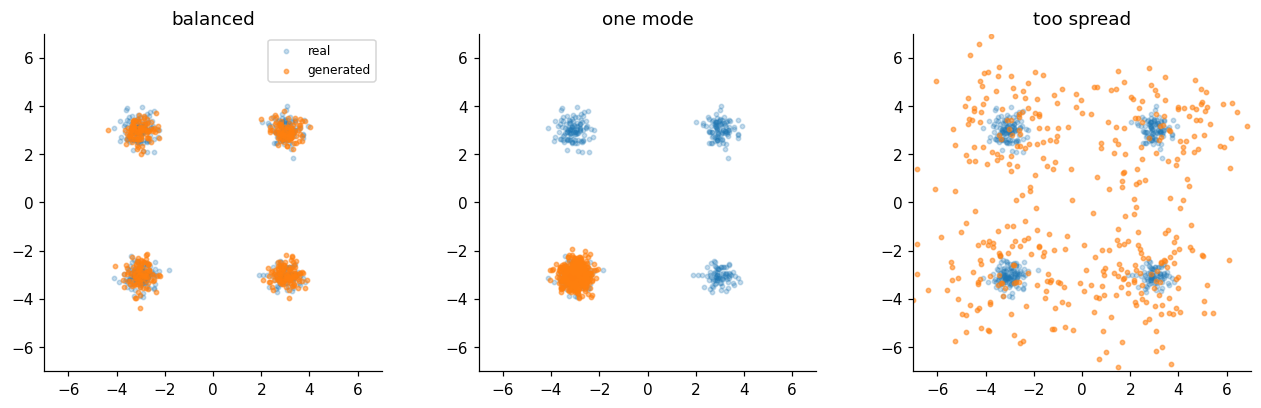

,precision,recall,density,coverage
balanced,0.990,0.98,1.082,0.982
one mode,0.988,0.29,1.049,0.292
too spread,0.252,1.00,0.171,0.450


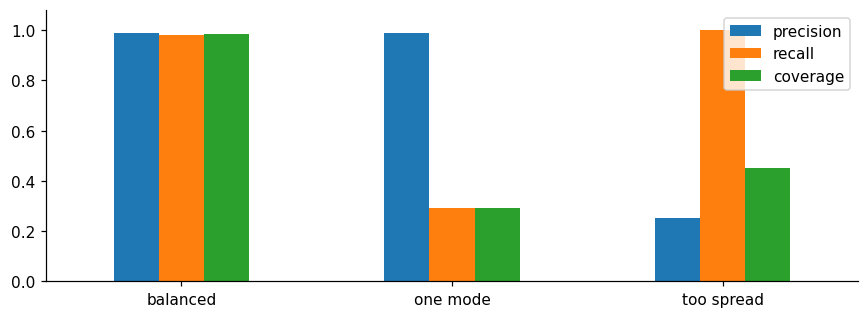

In [26]:
def prdc_features(real, generated, k=5):
    real, generated = feature_arrays(real, generated)
    if not 1 <= k < min(len(real), len(generated)):
        raise ValueError('Require 1 <= k < both sample counts')
    rr, gg, rg = cdist(real, real), cdist(generated, generated), cdist(real, generated)
    np.fill_diagonal(rr, np.inf); np.fill_diagonal(gg, np.inf)
    real_radius = np.partition(rr, k-1, axis=1)[:, k-1]
    gen_radius = np.partition(gg, k-1, axis=1)[:, k-1]
    in_real = rg < real_radius[:, None]
    in_gen = rg < gen_radius[None, :]
    return {'precision': in_real.any(axis=0).mean(),
            'recall': in_gen.any(axis=1).mean(),
            'density': in_real.sum(axis=0).mean()/k,
            'coverage': in_real.any(axis=1).mean()}

CENTERS = np.array([[-3,-3],[-3,3],[3,-3],[3,3]])
def islands(n, rng, modes=4, spread=0.35):
    labels = rng.integers(modes, size=n)
    return CENTERS[labels] + rng.normal(0, spread, (n,2))

rng3 = np.random.default_rng(SEED + 3)
real_cloud = islands(400, rng3)
generators = {'balanced': islands(400, rng3),
              'one mode': islands(400, rng3, modes=1),
              'too spread': islands(400, rng3, spread=1.6)}
fig, axs = plt.subplots(1,3, figsize=(12,3.7))
for ax, (name, generated) in zip(axs, generators.items()):
    ax.scatter(*real_cloud.T, s=8, alpha=.25, label='real')
    ax.scatter(*generated.T, s=8, alpha=.55, label='generated')
    ax.set(title=name, xlim=(-7,7), ylim=(-7,7)); ax.set_aspect('equal')
axs[0].legend(fontsize=8)
finish_figure('03_quality_coverage_clouds')
diagnosis = pd.DataFrame({name: prdc_features(real_cloud, generated, k=5)
                          for name, generated in generators.items()}).T
display(diagnosis.round(3))
diagnosis[['precision','recall','coverage']].plot.bar(figsize=(8,3), ylim=(0,1.08), rot=0)
finish_figure('03_quality_coverage_scores')

**What to notice:** one-mode outputs can fit the real region yet miss most variety. Scattered
outputs can lose precision while large generated circles inflate recall.


**Optional 2-minute activity:** change k=5 in the evaluation call to 2, then 10, keeping points
fixed. Larger circles make precision/recall/coverage nondecreasing; density can move either
way because it also divides by k. Changing a measuring rule is not improving a generator.

**Takeaway:** “Check plausible outputs and useful variety separately. Keep the feature
model, sample counts, and k fixed. Inspect examples as well as scores.”

Source: [official precision/recall/density/coverage definitions](https://github.com/clovaai/generative-evaluation-prdc).

### A brief historical metric: Inception Score (IS) · 

**Goal:** recognize why classifier confidence and class variety are not a complete evaluation.

**Key idea:** “A pretrained Inception classifier should confidently recognize each generated image,
while its predicted labels across the collection should be varied.”

Optional reference formula:

$$\mathrm{IS}=\exp\left(\mathbb{E}_{x\sim G}
D_{\mathrm{KL}}(p(y\mid x)\,\|\,p(y))\right).$$

Here x is a generated image; y is a classifier label; p(y|x) is the predicted label distribution
for one image; p(y) is its average over generated images. Higher rewards confident individual
predictions and a diverse overall predicted-label distribution. There is no universal good cutoff.

**Model connection:** unlike FID, which uses Inception FEATURES and a real reference set,
IS uses Inception CLASS PROBABILITIES and only the generated collection.

**Blind spot:** repeating one recognizable example per class can score well despite poor
within-class variety. It does not check agreement with the target real dataset, and ImageNet
labels may be inappropriate for your domain. Classifier confidence is not proof of realism.

**By the end:** students know the name and its limitation; no calculation is required.
Source: [original Inception Score paper](https://arxiv.org/abs/1606.03498).

### Recap

**Key idea:** “Choose the task first, then the metric. A measurement is evidence, not a verdict.”

| Task | Starting checks | What to inspect |
|---|---|---|
| Restore a particular photograph | Pixel/structure scores plus LPIPS | Alignment, lost detail, invented detail |
| Generate a new image collection | A fixed-protocol distribution score plus plausibility/coverage checks | Missing modes, implausible outputs, copying |

**Which networks are used?** MSE/PSNR/SSIM: none. LPIPS here: pretrained AlexNet plus
calibration weights. Standard FID/KID: Inception features. IS: Inception label probabilities.
Our toy Fréchet/MMD/neighborhood experiments: no pretrained network.

**Review questions and short answers:**

1. Why not compare each new cat to an arbitrary real cat? **No matching target exists.**
2. Can matching means/covariances hide different distributions? **Yes: axes versus corners.**
3. What does a realistic one-island generator miss? **Variety: inspect recall and coverage.**
4. Does high IS prove matching real data? **No: it has no real-reference comparison.**
5. What must be fixed in a fair comparison? **Feature model/preprocessing, sample counts,
   and metric settings such as k; report these along with variability.**

